# 01 · Accessibility: travel time to Canary Wharf with and without the tunnel

For every street node in the study area we compute the time to One Canada
Square (standing in for "Canary Wharf jobs") by:

- **walking**, over the OSM walk network
- **cycling**, over the OSM bike network
- **public transport**, approximated as walk-to-station + a fixed door-to-door
  time from each station to Canary Wharf (in-vehicle + average wait + change
  penalty; see `STATION_MINUTES`, which is a rough hand-set table)

**Generalised access time** = min(walk, public transport). Cycling is kept as a
separate measure because most people don't cycle, but it's where the tunnel
changes things most.

The "after" scenario adds a tunnel edge between the portals. Its time is
length / speed + a delay at each portal for the lift (see `common.py`).


In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
from shapely.geometry import Point

from common import (
    BNG,
    CANARY_WHARF,
    CYCLE_KMH,
    DERIVED,
    FIGURES,
    NORTH_PORTAL,
    PORTAL_DELAY_MIN,
    RAW,
    SOUTH_PORTAL,
    STUDY_BBOX,
    TUNNEL_DETOUR,
    WALK_KMH,
    WGS84,
    attach_access,
    to_bng,
)

# The Rotherhithe road tunnel is legally walkable/cyclable but notoriously
# unpleasant (reportedly ~4 pedestrians a day), so by default treat it as unusable.
EXCLUDE_ROTHERHITHE_ROAD_TUNNEL = True

# Door-to-door minutes from boarding at the station to arriving at Canary Wharf
# (in-vehicle + half the headway + change penalty). Rough, hand-set.
STATION_MINUTES = {
    "South Quay": 4,
    "Crossharbour": 5,
    "Mudchute": 6,
    "Island Gardens": 8,
    "Westferry": 5,
    "Limehouse": 6,
    "Poplar": 5,
    "All Saints": 7,
    "Blackwall": 7,
    "Shadwell": 9,
    "Tower Gateway": 12,
    "Whitechapel": 6,
    "Canada Water": 5,
    "Bermondsey": 7,
    "North Greenwich": 5,
    "Canning Town": 7,
    "Surrey Quays": 12,
    "Rotherhithe": 12,
    "Wapping": 13,
    "New Cross Gate": 15,
    "New Cross": 15,
    "Queens Road Peckham": 18,
    "Deptford Bridge": 11,
    "Greenwich": 10,
    "Cutty Sark for Maritime Greenwich": 9,
    "Deptford": 20,
    "South Bermondsey": 20,
}

## Street networks

Cached as GraphML in `data/raw/` after the first download from OpenStreetMap.


In [2]:
def load_graph(kind: str) -> nx.MultiDiGraph:
    path = RAW / f"{kind}.graphml"
    if path.exists():
        return ox.load_graphml(path)
    G = ox.graph_from_bbox(STUDY_BBOX, network_type=kind, simplify=True)
    ox.save_graphml(G, path)
    return G


def prepare(G: nx.MultiDiGraph, kmh: float) -> nx.Graph:
    """Undirected, projected to BNG, with a travel-time (minutes) edge weight."""
    G = ox.project_graph(G, to_crs=BNG)
    U = nx.Graph()
    U.add_nodes_from(G.nodes(data=True))
    for u, v, d in G.edges(data=True):
        name = d.get("name", "")
        name = " / ".join(name) if isinstance(name, list) else str(name)
        if EXCLUDE_ROTHERHITHE_ROAD_TUNNEL and "Rotherhithe Tunnel" in name:
            continue
        minutes = d["length"] / (kmh * 1000 / 60)
        if not U.has_edge(u, v) or U[u][v]["minutes"] > minutes:
            U.add_edge(u, v, minutes=minutes)
    return U


walk = prepare(load_graph("walk"), WALK_KMH)
bike = prepare(load_graph("bike"), CYCLE_KMH)


def add_greenwich_foot_tunnel(bike: nx.Graph) -> None:
    """OSM's bike network drops the Greenwich foot tunnel (cyclists must dismount),
    which makes Greenwich/Deptford look cut off. Add it back at walking pace plus lifts."""
    raw = ox.project_graph(load_graph("walk"), to_crs=BNG)
    ends = {n for u, v, d in raw.edges(data=True) if "Greenwich Foot Tunnel" in str(d.get("name", "")) for n in (u, v)}
    pts = {n: Point(raw.nodes[n]["x"], raw.nodes[n]["y"]) for n in ends}
    a, b = max(((p, q) for p in pts for q in pts), key=lambda pq: pts[pq[0]].distance(pts[pq[1]]))
    bxy = {n: Point(d["x"], d["y"]) for n, d in bike.nodes(data=True)}
    na = min(bxy, key=lambda n: bxy[n].distance(pts[a]))
    nb = min(bxy, key=lambda n: bxy[n].distance(pts[b]))
    minutes = pts[a].distance(pts[b]) / (WALK_KMH * 1000 / 60) + 2 * PORTAL_DELAY_MIN
    bike.add_edge(na, nb, minutes=minutes)
    print(f"Greenwich foot tunnel added to bike network: {pts[a].distance(pts[b]):.0f} m, {minutes:.1f} min")


add_greenwich_foot_tunnel(bike)
print(f"walk: {walk.number_of_nodes():,} nodes · bike: {bike.number_of_nodes():,} nodes")

Greenwich foot tunnel added to bike network: 379 m, 7.7 min
walk: 25,957 nodes · bike: 13,931 nodes


## Add the tunnel


In [3]:
def nearest_node(G: nx.Graph, lonlat) -> int:
    x, y = to_bng(lonlat)
    xs = np.array([d["x"] for _, d in G.nodes(data=True)])
    ys = np.array([d["y"] for _, d in G.nodes(data=True)])
    return list(G.nodes)[int(np.argmin((xs - x) ** 2 + (ys - y) ** 2))]


portal_gap_m = Point(to_bng(SOUTH_PORTAL)).distance(Point(to_bng(NORTH_PORTAL)))
tunnel_m = portal_gap_m * TUNNEL_DETOUR
print(f"Portal-to-portal: {portal_gap_m:.0f} m straight line, {tunnel_m:.0f} m assumed tunnel length")


def with_tunnel(G: nx.Graph, kmh: float) -> nx.Graph:
    H = G.copy()
    minutes = tunnel_m / (kmh * 1000 / 60) + 2 * PORTAL_DELAY_MIN
    H.add_edge(nearest_node(G, SOUTH_PORTAL), nearest_node(G, NORTH_PORTAL), minutes=minutes)
    print(f"  tunnel edge at {kmh} km/h: {minutes:.1f} min portal to portal")
    return H


walk_after = with_tunnel(walk, WALK_KMH)
bike_after = with_tunnel(bike, CYCLE_KMH)

Portal-to-portal: 460 m straight line, 506 m assumed tunnel length
  tunnel edge at 4.8 km/h: 9.3 min portal to portal


  tunnel edge at 15.0 km/h: 5.0 min portal to portal


## Times to Canary Wharf


In [4]:
def times_to(G: nx.Graph, lonlat) -> pd.Series:
    return pd.Series(nx.single_source_dijkstra_path_length(G, nearest_node(G, lonlat), weight="minutes"))


stations = gpd.read_file(RAW / "stations.gpkg")
stations = stations[stations["name"].isin(STATION_MINUTES)].drop_duplicates("name")
missing = set(STATION_MINUTES) - set(stations["name"])
print("Stations matched:", len(stations), "| not found in OSM:", missing or "none")


def pt_time(G: nx.Graph) -> pd.Series:
    """Walk to the best station + that station's fixed time to Canary Wharf."""
    best = None
    for name, geom in zip(stations["name"], stations.geometry):
        t = times_to(G, (geom.x, geom.y)) + STATION_MINUTES[name]
        best = t if best is None else best.combine(t, min, fill_value=np.inf)
    if best is None:
        raise ValueError("No stations matched in OSM")
    return best


nodes = pd.DataFrame(
    {"x": [d["x"] for _, d in walk.nodes(data=True)], "y": [d["y"] for _, d in walk.nodes(data=True)]},
    index=list(walk.nodes),
)
nodes["walk_before"] = times_to(walk, CANARY_WHARF)
nodes["walk_after"] = times_to(walk_after, CANARY_WHARF)
# The tunnel also shortens walks to Isle of Dogs stations, so recompute PT after.
nodes["pt_before"] = pt_time(walk)
nodes["pt_after"] = pt_time(walk_after)
nodes["access_before"] = nodes[["walk_before", "pt_before"]].min(axis=1)
nodes["access_after"] = nodes[["walk_after", "pt_after"]].min(axis=1)
nodes = nodes.dropna(subset=["access_before"])

bike_nodes = pd.DataFrame(
    {"x": [d["x"] for _, d in bike.nodes(data=True)], "y": [d["y"] for _, d in bike.nodes(data=True)]},
    index=list(bike.nodes),
)
bike_nodes["cycle_before"] = times_to(bike, CANARY_WHARF)
bike_nodes["cycle_after"] = times_to(bike_after, CANARY_WHARF)
bike_nodes = bike_nodes.dropna()

Stations matched: 27 | not found in OSM: none


## Save a lookup so later notebooks can attach times to any point


In [5]:
walk_gdf = gpd.GeoDataFrame(nodes, geometry=gpd.points_from_xy(nodes.x, nodes.y), crs=BNG)
bike_gdf = gpd.GeoDataFrame(bike_nodes, geometry=gpd.points_from_xy(bike_nodes.x, bike_nodes.y), crs=BNG)
walk_gdf.drop(columns=["x", "y"]).to_file(DERIVED / "access_nodes.gpkg", layer="walk_pt", driver="GPKG")
bike_gdf.drop(columns=["x", "y"]).to_file(DERIVED / "access_nodes.gpkg", layer="cycle", driver="GPKG")

## Sanity check: a few named places


In [ ]:
places = gpd.GeoDataFrame(
    {
        "place": [
            "Durand's Wharf (south portal)",
            "Surrey Docks Farm",
            "Greenland Dock",
            "Canada Water station",
            "Rotherhithe station",
            "Bermondsey station",
            "Deptford High Street",
            "Wapping station",
            "Island Gardens station",
        ]
    },
    geometry=[
        Point(SOUTH_PORTAL),
        Point(-0.03343, 51.49959),
        Point(-0.03960, 51.49465),
        Point(-0.04910, 51.49847),
        Point(-0.05199, 51.50061),
        Point(-0.06374, 51.49785),
        Point(-0.02600, 51.47507),
        Point(-0.05668, 51.50401),
        Point(-0.00960, 51.48780),
    ],
    crs=WGS84,
)
check = attach_access(places)  # defined in common.py
cols = [
    "place",
    "walk_before",
    "walk_after",
    "pt_before",
    "pt_after",
    "access_before",
    "access_after",
    "cycle_before",
    "cycle_after",
]
check[cols].round(1)

,place,walk_before,walk_after,pt_before,pt_after,access_before,access_after,cycle_before,cycle_after
0,Durand's Wharf (south portal),103.5,18.0,30.1,24.2,30.1,18.0,35.5,8.4
1,Surrey Docks Farm,102.3,21.8,28.9,28.0,28.9,21.8,35.5,10.6
2,Greenland Dock,85.1,38.0,23.4,23.4,23.4,23.4,34.1,12.4
3,Canada Water station,94.4,41.5,6.6,6.6,6.6,6.6,30.1,14.5
4,Rotherhithe station,89.9,45.7,12.2,12.2,12.2,12.2,28.7,15.2
5,Bermondsey station,80.3,56.0,9.2,9.2,9.2,9.2,25.3,18.9
6,Deptford High Street,68.3,68.3,21.5,21.5,21.5,21.5,31.2,24.1
7,Wapping station,50.5,50.5,13.7,13.7,13.7,13.7,14.2,14.2
8,Island Gardens station,33.7,33.7,8.7,8.7,8.7,8.7,13.1,13.1


## Maps: minutes saved


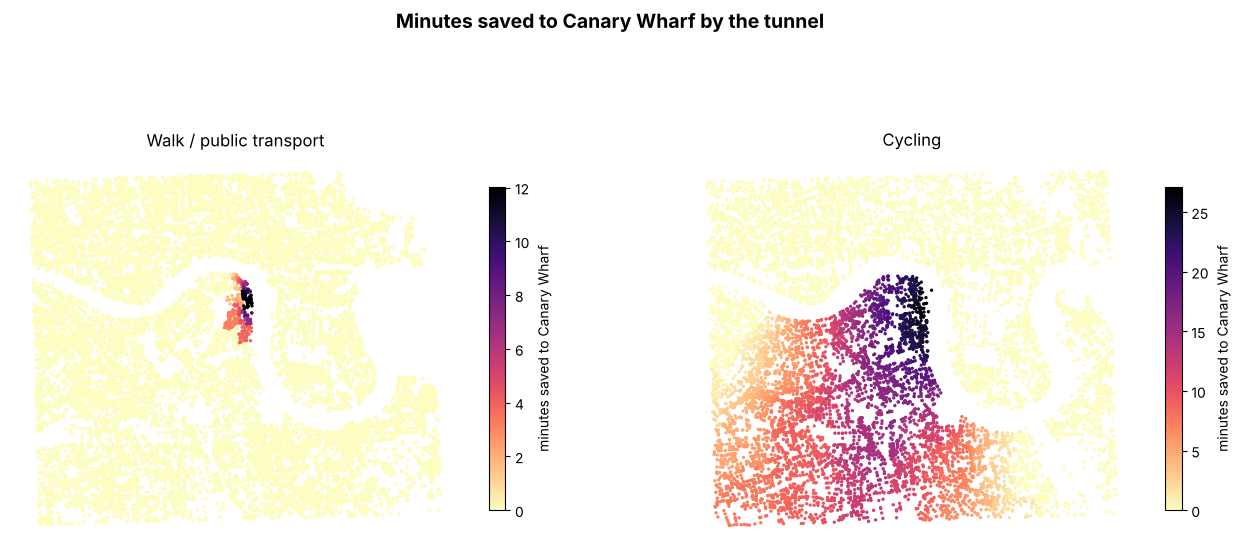

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (gdf, col_b, col_a, title) in zip(
    axes,
    [
        (walk_gdf, "access_before", "access_after", "Walk / public transport"),
        (bike_gdf, "cycle_before", "cycle_after", "Cycling"),
    ],
):
    saved = (gdf[col_b] - gdf[col_a]).clip(lower=0)
    gdf.assign(saved=saved).sort_values("saved").plot(
        ax=ax,
        column="saved",
        cmap="magma_r",
        markersize=2,
        legend=True,
        vmin=0,
        legend_kwds={"label": "minutes saved to Canary Wharf", "shrink": 0.6},
    )
    ax.set_title(title)
    ax.set_axis_off()
fig.suptitle("Minutes saved to Canary Wharf by the tunnel", fontsize=14, fontweight="bold")
fig.savefig(FIGURES / "01_minutes_saved.png", dpi=150, bbox_inches="tight")